In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [20]:
df_org = pd.read_csv("./house_train.csv")
df = df_org.copy()
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [21]:
print(df.shape)
print(df.dtypes.value_counts())
isnull_series = df.isnull().sum()
print(isnull_series[isnull_series > 0].sort_values(ascending = False))

(1460, 81)
object     43
int64      35
float64     3
dtype: int64
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


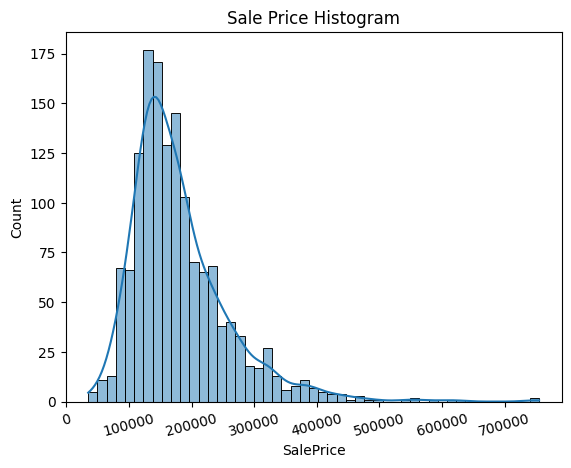

In [22]:
plt.title("Sale Price Histogram")
plt.xticks(rotation = 15)
sns.histplot(df["SalePrice"], kde = True)
plt.show()

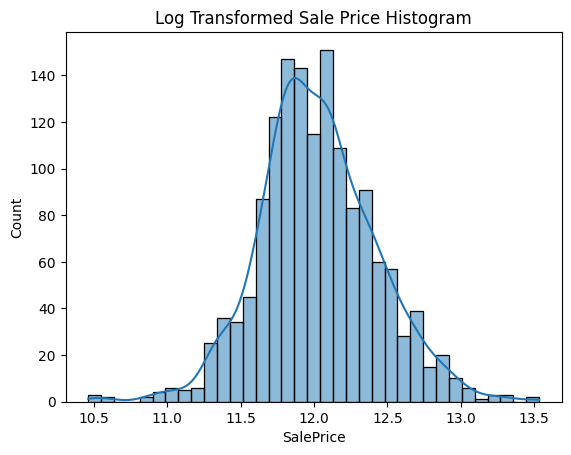

In [23]:
plt.title("Log Transformed Sale Price Histogram")
log_SalePrice = np.log1p(df["SalePrice"])
sns.histplot(log_SalePrice, kde = True)
plt.show()

In [24]:
org_SalePrice = df["SalePrice"]
df["SalePrice"] = np.log1p(df["SalePrice"])

df.drop(["Id", "PoolQC", "MiscFeature", "Alley", "Fence",
"FireplaceQu"], axis = 1, inplace = True)
df.fillna(df.mean(), inplace = True)

null_column_count = df.isnull().sum()[df.isnull().sum() > 0]
print(df.dtypes[null_column_count.index])

MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


In [25]:
print(df.shape)
df_ohe = pd.get_dummies(df)
print(df_ohe.shape)

(1460, 75)
(1460, 271)


In [26]:
null_column_count = df_ohe.isnull().sum()[df_ohe.isnull().sum() > 0]
print(df_ohe.dtypes[null_column_count.index])

Series([], dtype: object)


In [29]:
def get_rmse(model):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    print(model.__class__.__name__, np.round(rmse, 3))
    return rmse

def get_rmses(models):
    rmses = []
    for model in models:
        rmse = get_rmse(model)
        rmses.append(rmse)

    return rmses


In [30]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target = df_ohe["SalePrice"]
X_features = df_ohe.drop(["SalePrice"], axis = 1, inplace = False)

X_train, X_test, y_train, y_test = train_test_split(X_features,
                y_target, test_size = 0.3, random_state = 156)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)

ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)

lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

LinearRegression 0.129
Ridge 0.124
Lasso 0.172


[0.12904191499497347, 0.12429663821697717, 0.17162071661564268]

In [31]:
def get_top_bottom_coef(model):
    coef = pd.Series(model.coef_, index = X_features.columns)
    coef_high = coef.sort_values(ascending = False).head(10)
    coef_low = coef.sort_values(ascending = False).tail(10)
    return coef_high, coef_low

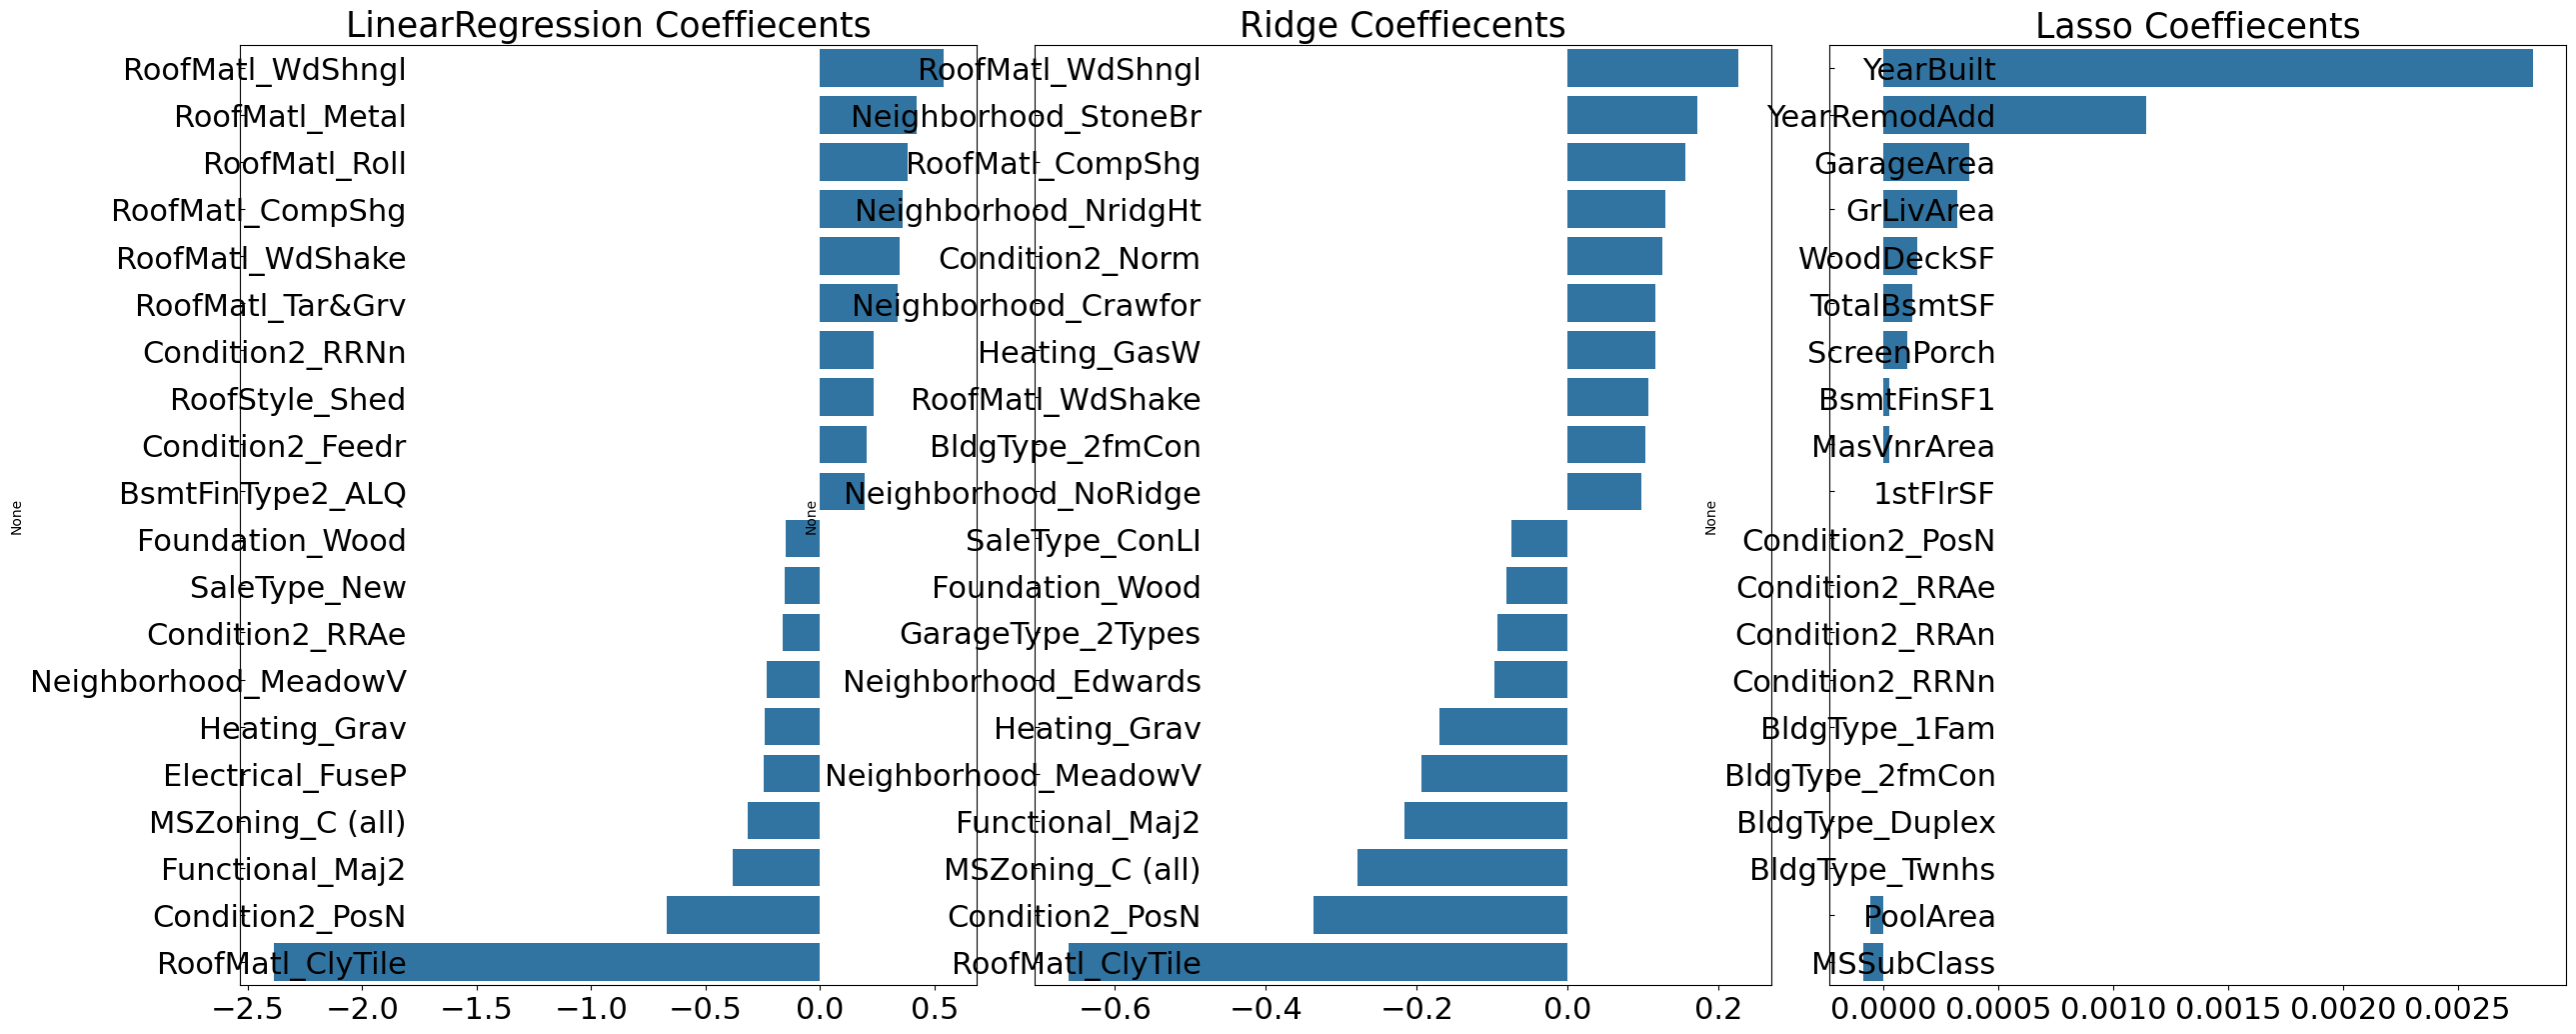

In [32]:
def visualize_coef(models):
    fig, axs = plt.subplots(figsize = (24, 10), nrows = 1, ncols = 3)
    fig.tight_layout()
    for i_num, model in enumerate(models):
        coef_high, coef_low = get_top_bottom_coef(model)
        coef_concat = pd.concat([coef_high, coef_low])
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents',
                             size = 25)
        axs[i_num].tick_params(axis = 'y', direction = 'in', pad = -120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x = coef_concat.values, y = coef_concat.index,
                    ax = axs[i_num])

model = [lr_reg, ridge_reg, lasso_reg]
visualize_coef(models)